OEFENING VOORBEELD 3.2.1 p21

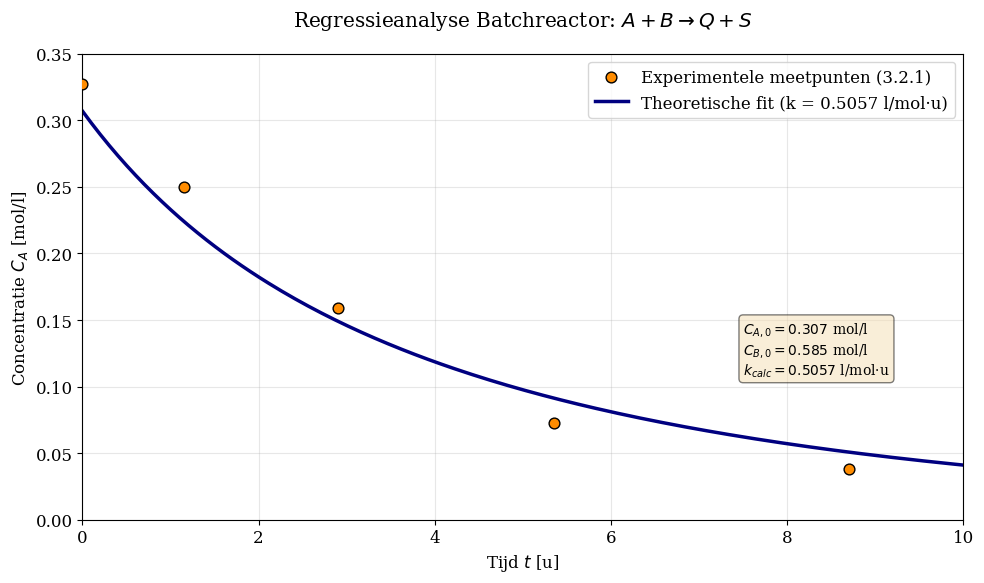

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. CONFIGURATIE & DATA ---
# Gebruik je chgnet_env kernel voor deze berekeningen
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.figsize": (10, 6)
})

# Data uit voorbeeld 3.2.1 (Pagina 20)
t_exp = np.array([0, 1.15, 2.90, 5.35, 8.70])       # Tijd in uren
Ca_exp = np.array([0.327, 0.250, 0.1590, 0.073, 0.038]) # Conc A in mol/l

# Initiële condities
Ca0 = 0.307
Cb0 = 0.585
delta = Cb0 - Ca0  # Verschil in beginconcentraties (M in de theorie)

# --- 2. ANALYTISCH MODEL EN REGRESSIE ---
def model_Ca(t, k):
    """
    Analytische oplossing voor Ca(t) voor een 2de orde reactie A + B -> Producten.
    Afgeleid uit vergelijking (3.11) in de cursus.
    """
    numerator = Ca0 * delta
    denominator = Cb0 * np.exp(k * delta * t) - Ca0
    return numerator / denominator

# Voer de niet-lineaire regressie uit om 'k' te vinden
popt, pcov = curve_fit(model_Ca, t_exp, Ca_exp, p0=[0.5])
k_fit = popt[0]

# --- 3. THEORETISCHE FIT BEREKENEN ---
# Maak een fijne tijdsas voor een vloeiende theoretische lijn
t_fit = np.linspace(0, 10, 200)
Ca_theoretical = model_Ca(t_fit, k_fit)

# --- 4. VISUALISATIE ---
plt.figure()

# Plot de experimentele meetpunten
plt.scatter(t_exp, Ca_exp, color='darkorange', s=60, label='Experimentele meetpunten (3.2.1)', edgecolors='k', zorder=3)

# Plot de theoretische fit
plt.plot(t_fit, Ca_theoretical, color='navy', linestyle='-', linewidth=2.5, label=f'Theoretische fit (k = {k_fit:.4f} l/mol·u)', zorder=2)

# Opmaken van de grafiek
plt.title(r'Regressieanalyse Batchreactor: $A + B \rightarrow Q + S$', pad=20)
plt.xlabel('Tijd $t$ [u]')
plt.ylabel('Concentratie $C_A$ [mol/l]')
plt.xlim(0, 10)
plt.ylim(0, 0.35)
plt.legend(frameon=True, loc='upper right')

# Voeg een tekstbox toe met de parameters (handig voor je PhD verslag)
textstr = '\n'.join((
    r'$C_{A,0} = %.3f$ mol/l' % (Ca0, ),
    r'$C_{B,0} = %.3f$ mol/l' % (Cb0, ),
    r'$k_{calc} = %.4f$ l/mol·u' % (k_fit, )))
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
plt.text(7.5, 0.15, textstr, fontsize=10, verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

OEFENING 3.3.1

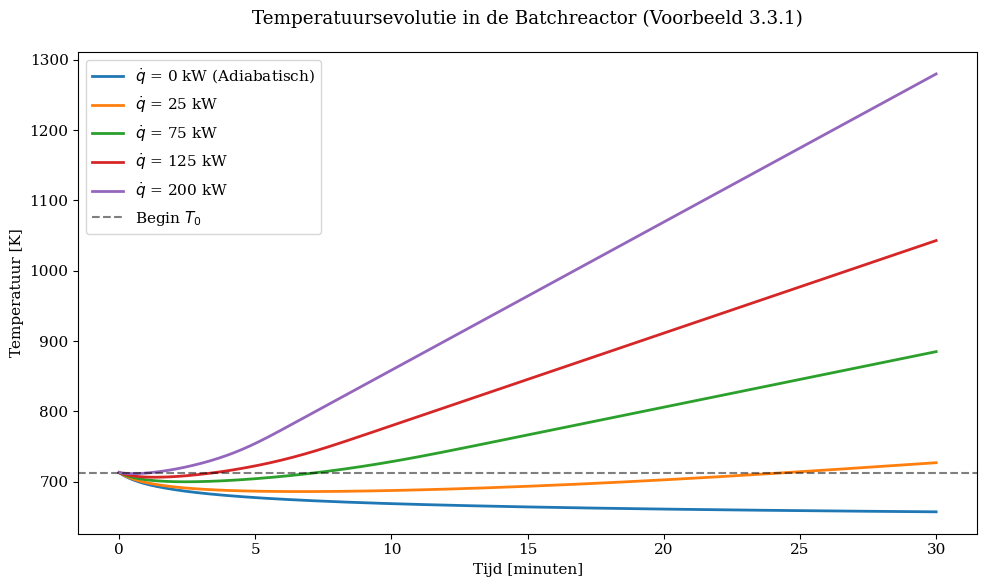

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. PARAMETERS (Data uit pagina 22-23 van de cursus) ---
m_totaal = 227.0      # kg olie
cp = 2.51             # kJ/kgK
T0 = 713.0            # K (begintemperatuur)
delta_rH = 62800.0    # kJ/kmol (endotherme reactie)
X_target = 0.70       # Beoogde omzetting (70%)

# Berekening van nA,0 (kmol)
# Cursus: 0.156 kg azijnzuur per kg voeding bij volledige ontbinding
# Molaire massa azijnzuur (CH3COOH) = 60.05 g/mol = 60.05 kg/kmol
m_zuur_totaal = m_totaal * 0.156
nA0 = m_zuur_totaal / 60.05  # kmol

# Kinetiek (Arrhenius aanname voor dit type reactie)
# Deze waarden zijn gekozen om de tijdschaal van de cursus (minuten) te matchen
A = 1.1e11            # Pre-exponentiële factor (1/s)
Ea = 1.8e5            # Activeringsenergie (J/mol)
R = 8.314             # Gasconstante (J/molK)

# --- 2. HET MODEL (ODE SYSTEEM) ---
def model(t, y, q_dot):
    nA, T = y
    
    # Snelheidsconstante k(T)
    k = A * np.exp(-Ea / (R * T))
    
    # Molbalans: dnA/dt = -k * nA
    dnA_dt = -k * nA
    
    # Enthalpiebalans: m*cp*dT/dt = q_dot - (Rate * delta_rH)
    # Let op: Rate is -dnA_dt (hoeveelheid die wegreageert)
    # delta_rH is positief (endotherm), dus verbruikt warmte
    dT_dt = (q_dot - (delta_rH * k * nA)) / (m_totaal * cp)
    
    return [dnA_dt, dT_dt]

# --- 3. SIMULATIE VOOR VERSCHILLENDE WARMREDEBIETEN ---
# We kiezen debieten die anders zijn dan de cursus: 0, 25, 75, 125, 200 kW
q_dots = [0, 25, 75, 125, 200] # kW (kJ/s)
t_span = (0, 1800)             # 30 minuten (1800 seconden)
t_eval = np.linspace(0, 1800, 500)

plt.figure(figsize=(10, 6))

for q in q_dots:
    sol = solve_ivp(model, t_span, [nA0, T0], args=(q,), t_eval=t_eval)
    
    # Label bepalen
    label = rf"$\dot{{q}}$ = {q} kW"
    if q == 0: label += " (Adiabatisch)"
    
    plt.plot(sol.t / 60, sol.y[1], label=label, linewidth=2)

# --- 4. GRAFIEK OPMAAK (PhD Stijl) ---
plt.title('Temperatuursevolutie in de Batchreactor (Voorbeeld 3.3.1)', pad=20)
plt.xlabel('Tijd [minuten]')
plt.ylabel('Temperatuur [K]')
plt.axhline(T0, color='black', linestyle='--', alpha=0.5, label="Begin $T_0$")
plt.legend(loc='best', frameon=True)
plt.grid(False)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

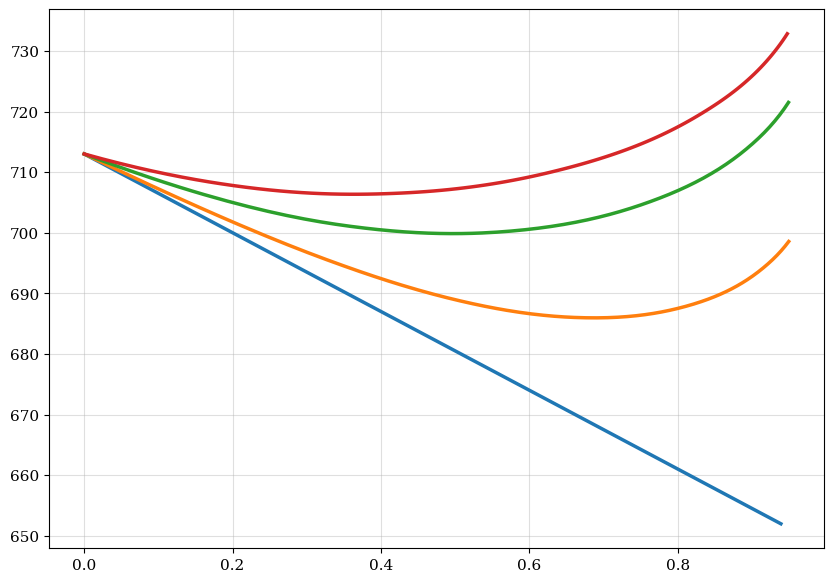

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. PARAMETERS (Identiek aan vorig voorbeeld) ---
m_totaal = 227.0      # kg
cp = 2.51             # kJ/kgK
T0 = 713.0            # K
delta_rH = 62800.0    # kJ/kmol
nA0 = (227.0 * 0.156) / 60.05  # kmol

A = 1.1e11            
Ea = 1.8e5            
R = 8.314             

def model(t, y, q_dot):
    nA, T = y
    k = A * np.exp(-Ea / (R * T))
    dnA_dt = -k * nA
    dT_dt = (q_dot - (delta_rH * k * nA)) / (m_totaal * cp)
    return [dnA_dt, dT_dt]

# --- 2. SIMULATIE ---
q_dots = [0, 25, 75, 125, 200] 
t_span = (0, 3600) # Verlengd naar 60 min om hoge omzetting te garanderen
t_eval = np.linspace(0, 3600, 1000)

plt.figure(figsize=(10, 7))

for q in q_dots:
    sol = solve_ivp(model, t_span, [nA0, T0], args=(q,), t_eval=t_eval)
    
    # Bereken omzetting X = (nA0 - nA) / nA0
    nA_waarden = sol.y[0]
    X = (nA0 - nA_waarden) / nA0
    T = sol.y[1]
    
    # Filter de data: we stoppen bij X = 0.95 om de grafiek overzichtelijk te houden
    mask = X <= 0.95
    plt.plot(X[mask], T[mask], label=rf"$\dot{{q}}$ = {q} kW", linewidth=2.5)

# --- 3. OPMAAK ---
plt.title('Reactortraject: Temperatuur vs. Omzetting (Voorbeeld 3.3.1)', pad=20)
plt.xlabel('Omzetting $X$ [-]')
plt.ylabel('Temperatuur $T$ [K]')
plt.axvline(0.70, color='red', linestyle=':', label='Target $X=0.70$')

# Annotatie voor de adiabatische lijn (Sectie 3.3, vergelijking 3.16)
plt.annotate('Adiabatische daling (lineair)', xy=(0.3, 670), xytext=(0.1, 640),
             arrowprops=dict(facecolor='black', arrowstyle='->'))

plt.legend(loc='best')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Example of batch vs PFR vs CSTR 
conversion profiles and residence time distributions for each reactor type.

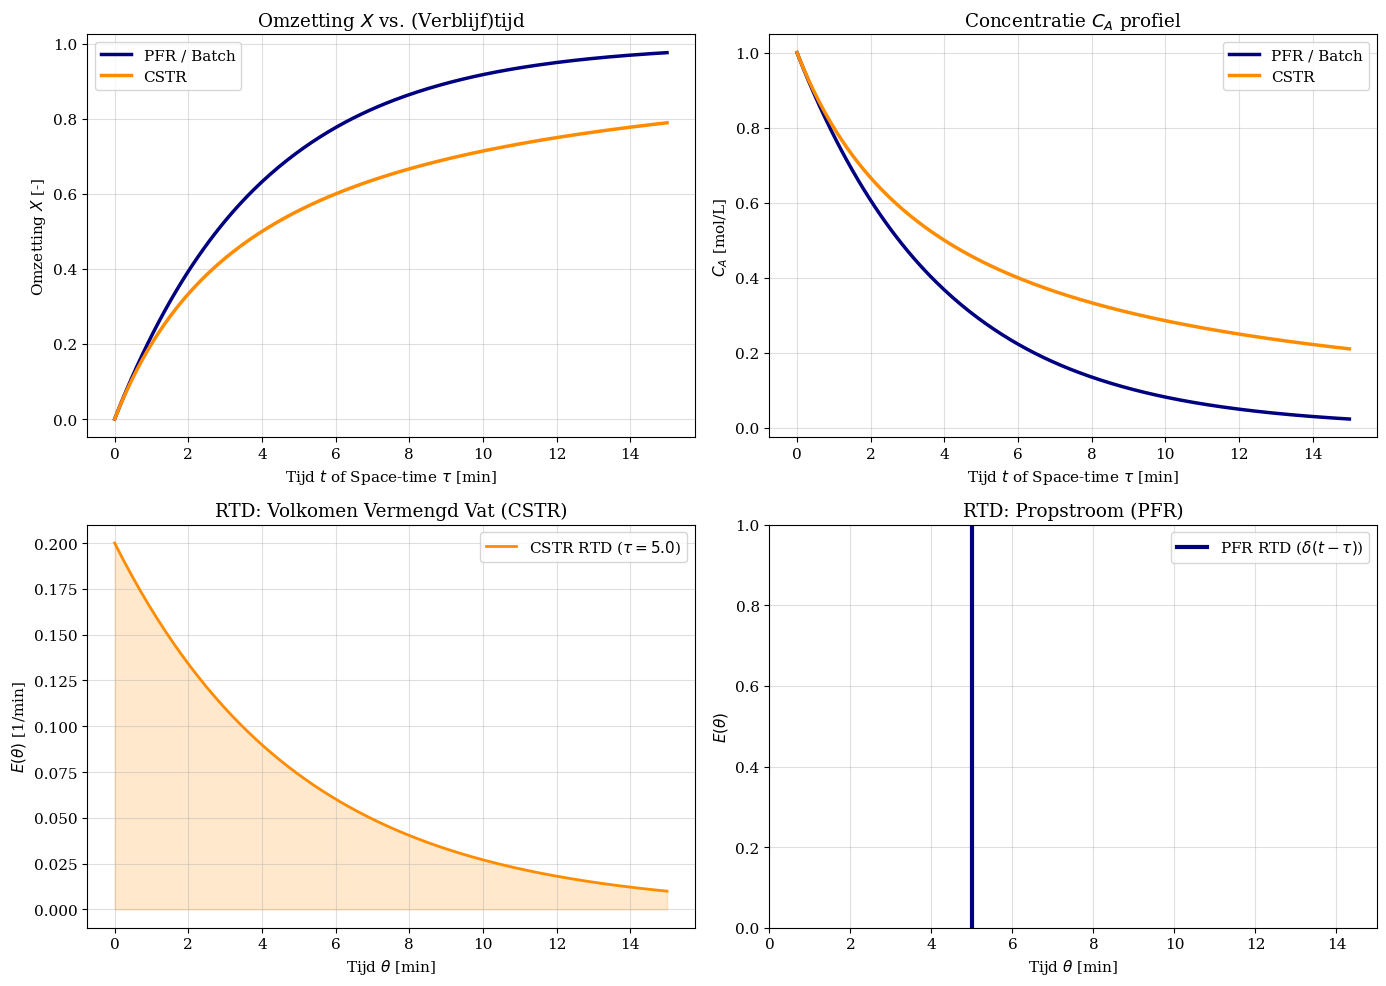

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. PARAMETERS & CONFIGURATIE ---
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "figure.figsize": (12, 10)
})

k = 0.25            # Snelheidsconstante [1/min] (fictief)
Ca0 = 1.0           # Beginconcentratie [mol/L]
tau_max = 15        # Maximale verblijftijd/tijd [min]
t_eval = np.linspace(0, tau_max, 200)

# --- 2. MODELLERING ---

# A. BATCH / PFR (Numeriek)
# dCa/dt = -k*Ca
def batch_pfr_model(t, Ca):
    return -k * Ca

sol_pfr = solve_ivp(batch_pfr_model, [0, tau_max], [Ca0], t_eval=t_eval)
X_pfr = (Ca0 - sol_pfr.y[0]) / Ca0

# B. CSTR (Algebraïsch - Sectie 5.3)
# Ca = Ca0 / (1 + k*tau)
Ca_cstr = Ca0 / (1 + k * t_eval)
X_cstr = (Ca0 - Ca_cstr) / Ca0

# C. RTD FUNCTIES (Hoofdstuk 8)
# PFR: Dirac-delta (benaderd met een smalle piek voor visualisatie)
def E_pfr(t, tau_mean):
    return np.where(np.abs(t - tau_mean) < 0.1, 10, 0) # Visualisatie-hulp

# CSTR: E(t) = (1/tau) * exp(-t/tau)
tau_mean = 5.0 # We bekijken de RTD voor een gemiddelde verblijftijd van 5 min
E_cstr = (1/tau_mean) * np.exp(-t_eval/tau_mean)

# --- 3. VISUALISATIE ---
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Grafiek 1: Omzetting X vs Tijd/Space-time
axs[0, 0].plot(t_eval, X_pfr, color='navy', lw=2.5, label='PFR / Batch')
axs[0, 0].plot(t_eval, X_cstr, color='darkorange', lw=2.5, label='CSTR')
axs[0, 0].set_title(rf'Omzetting $X$ vs. (Verblijf)tijd')
axs[0, 0].set_xlabel(rf'Tijd $t$ of Space-time $\tau$ [min]')
axs[0, 0].set_ylabel(rf'Omzetting $X$ [-]')
axs[0, 0].legend()

# Grafiek 2: Concentratie Ca vs Tijd/Space-time
axs[0, 1].plot(t_eval, sol_pfr.y[0], color='navy', lw=2.5, label='PFR / Batch')
axs[0, 1].plot(t_eval, Ca_cstr, color='darkorange', lw=2.5, label='CSTR')
axs[0, 1].set_title(rf'Concentratie $C_A$ profiel')
axs[0, 1].set_xlabel(rf'Tijd $t$ of Space-time $\tau$ [min]')
axs[0, 1].set_ylabel(rf'$C_A$ [mol/L]')
axs[0, 1].legend()

# Grafiek 3: RTD van de CSTR (Hoofdstuk 8.0.1)
axs[1, 0].plot(t_eval, E_cstr, color='darkorange', lw=2, label=rf'CSTR RTD ($\tau={tau_mean}$)')
axs[1, 0].fill_between(t_eval, E_cstr, color='darkorange', alpha=0.2)
axs[1, 0].set_title(rf'RTD: Volkomen Vermengd Vat (CSTR)')
axs[1, 0].set_xlabel(rf'Tijd $\theta$ [min]')
axs[1, 0].set_ylabel(rf'$E(\theta)$ [1/min]')
axs[1, 0].legend()

# Grafiek 4: RTD van de PFR (Hoofdstuk 8.0.2 principe)
axs[1, 1].axvline(tau_mean, color='navy', lw=3, label=rf'PFR RTD ($\delta(t-\tau)$)')
axs[1, 1].set_title(rf'RTD: Propstroom (PFR)')
axs[1, 1].set_xlabel(rf'Tijd $\theta$ [min]')
axs[1, 1].set_ylabel(rf'$E(\theta)$')
axs[1, 1].set_xlim(0, tau_max)
axs[1, 1].legend()

plt.tight_layout()
plt.show()

Example of product concentration vs time for CSTR and PFR


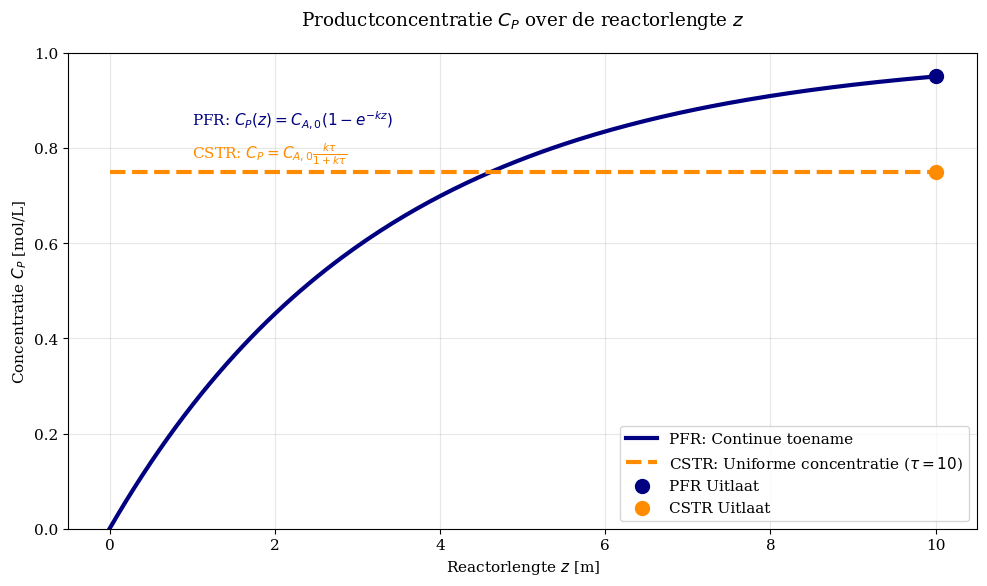

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. PARAMETERS ---
k = 0.3              # Snelheidsconstante [1/min]
Ca0 = 1.0            # Inlaatconcentratie reagens A [mol/L]
Cp0 = 0.0            # Inlaatconcentratie product P [mol/L]
L = 10               # Totale reactorlengte (fictieve eenheid)
z = np.linspace(0, L, 200) # Lengte-as

# --- 2. BEREKENINGEN ---

# PFR: Productconcentratie neemt exponentieel toe langs de lengte z
# Cp(z) = Ca0 * (1 - exp(-k * z/v)) -> we nemen v (snelheid) = 1 voor gemak
Cp_pfr = Ca0 * (1 - np.exp(-k * z))

# CSTR: Productconcentratie is uniform over de gehele lengte/volume
# Cp_uit = Ca0 * (k * tau / (1 + k * tau))
# We vergelijken met een CSTR die dezelfde totale verblijftijd heeft als de PFR (tau = L)
tau_totaal = L
Cp_cstr_final = Ca0 * (k * tau_totaal / (1 + k * tau_totaal))
Cp_cstr = np.full_like(z, Cp_cstr_final)

# --- 3. VISUALISATIE ---
plt.figure(figsize=(10, 6))

# PFR Profiel
plt.plot(z, Cp_pfr, label='PFR: Continue toename', color='navy', lw=3)

# CSTR Profiel (Uniforme waarde)
plt.plot(z, Cp_cstr, label=f'CSTR: Uniforme concentratie ($\\tau={L}$)', 
         color='darkorange', lw=3, linestyle='--')

# Grafiek opmaak
plt.title(r'Productconcentratie $C_P$ over de reactorlengte $z$', pad=20)
plt.xlabel('Reactorlengte $z$ [m]')
plt.ylabel('Concentratie $C_P$ [mol/L]')

plt.legend(loc='lower right', frameon=True)
plt.grid(False)
plt.ylim(0, 1.0)

# Voeg annotatie toe over de mengcondities
plt.text(1, 0.85, r"PFR: $C_P(z) = C_{A,0}(1 - e^{-kz})$", fontsize=11, color='navy')
plt.text(1, 0.78, r"CSTR: $C_P = C_{A,0}\frac{k\tau}{1+k\tau}$", fontsize=11, color='darkorange')

plt.tight_layout()
plt.show()

Grafische weergave van 6.3.3 pseudohomogeen 2 dimensionaal model (temp en conc ifv reactordimensies)

$D_r\left( \frac{\partial^2C_A}{\partial r^2} + \frac{1}{r}\frac{\partial C_A}{\partial r}\right) -v\frac{\partial C}{\partial z}+r_a\rho_k(1-\epsilon)=0 \\
k_a\left( \frac{\partial^2T}{\partial r^2} + \frac{1}{r}\frac{\partial T}{\partial r}\right) -v\rho c_p\frac{\partial T}{\partial z}+r_a\rho_k(1-\epsilon)=0$

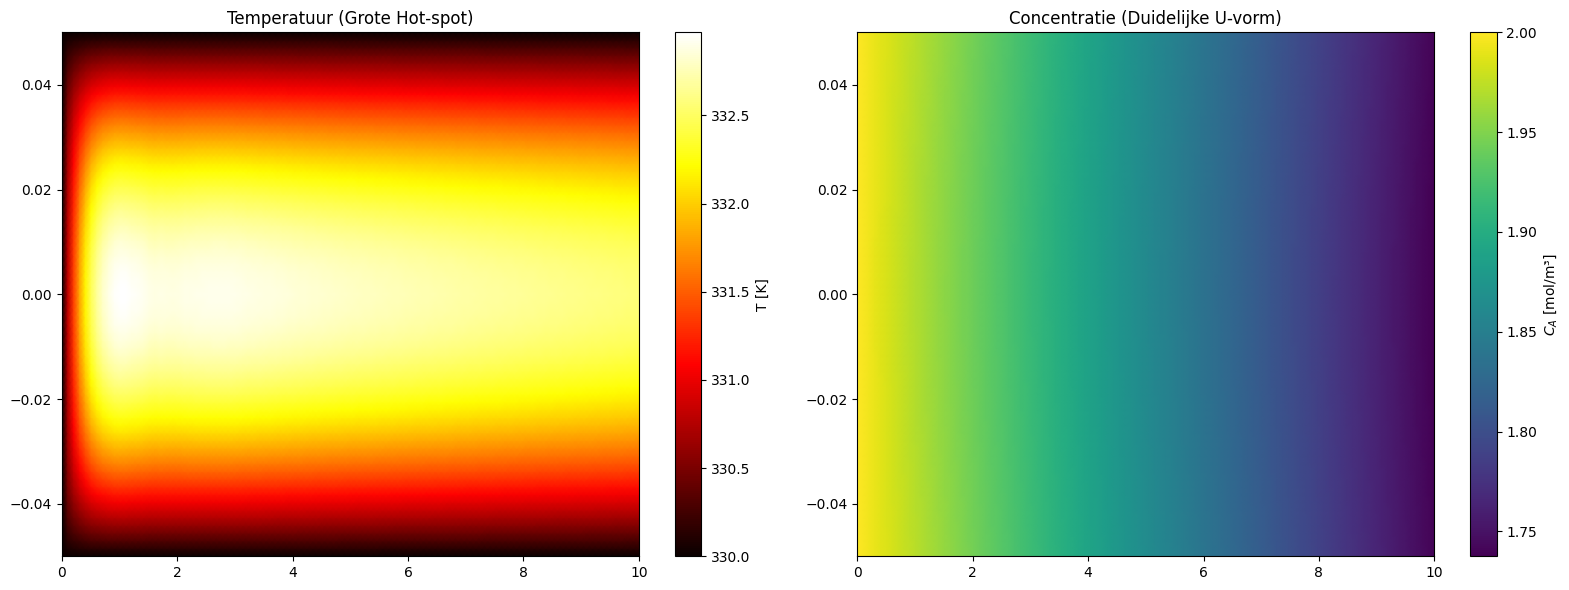

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- PARAMETERS (AANGEPAST VOOR ZICHTBARE GRADIENT) ---
L, R = 10.0, 0.05
nr = 35
dr = R / (nr - 1)
r_grid = np.linspace(0, R, nr)

v = 0.4             # Iets trager voor meer verblijftijd
rho_cp = 1200.0
kr = 1            # Minder geleiding = grotere T-verschillen
Dr = 5e-4           # Lagere dispersie = diepere concentratie-kuil
delta_rH = -350000.0# Sterker exotherm voor een grotere hot-spot
Ca0 = 2.0
Twtm, Tin = 300.0, 330.0

# KINETIEK: We maken de reactie "wild"
A, Ea = 1.6e11, 85000.0 # Hoge Ea maakt k(T) extreem gevoelig
R_gas = 8.314

def reactor_extreme(z, y):
    Ca = y[:nr]
    T = y[nr:]
    dCa_dz, dT_dz = np.zeros(nr), np.zeros(nr)
    
    for j in range(nr):
        k = A * np.exp(-Ea / (R_gas * T[j]))
        ra = -k * Ca[j]
        
        if j == 0: # Centrum
            radial_T = 2 * kr * (T[j+1] - T[j]) / (dr**2)
            radial_Ca = 2 * Dr * (Ca[j+1] - Ca[j]) / (dr**2)
        elif j == nr - 1: # Wand
            radial_T = kr * (Twtm - T[j]) / (dr**2)
            radial_Ca = Dr * (Ca[j-1] - Ca[j]) / (dr**2) # Randeffect
            dT_dz[j] = 0
            dCa_dz[j] = ra / v
            continue
        else:
            # Radiale afgeleiden (Sectie 6.3.3)
            radial_T = kr * ((T[j+1] - 2*T[j] + T[j-1])/(dr**2) + (1/r_grid[j])*(T[j+1]-T[j-1])/(2*dr))
            radial_Ca = Dr * ((Ca[j+1] - 2*Ca[j] + Ca[j-1])/(dr**2) + (1/r_grid[j])*(Ca[j+1]-Ca[j-1])/(2*dr))
            
        dCa_dz[j] = (radial_Ca + ra) / v
        dT_dz[j] = (radial_T + (ra * delta_rH)) / (v * rho_cp)
        
    return np.concatenate([dCa_dz, dT_dz])

# --- SIMULATIE ---
y0 = np.concatenate([np.full(nr, Ca0), np.full(nr, Tin)])
sol = solve_ivp(reactor_extreme, (0, L), y0, t_eval=np.linspace(0, L, 100), method='LSODA')

# --- PLOTTING ---
z_eval = sol.t
r_plot = np.concatenate([-np.flip(r_grid[1:]), r_grid])
Z, R_mesh = np.meshgrid(z_eval, r_plot)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# T-profiel
T_plot = np.vstack([np.flipud(sol.y[nr+1:, :]), sol.y[nr:, :]])
im1 = ax1.pcolormesh(Z, R_mesh, T_plot, cmap='hot', shading='gouraud')
plt.colorbar(im1, ax=ax1, label='T [K]')
ax1.set_title('Temperatuur (Grote Hot-spot)')

# Ca-profiel
Ca_plot = np.vstack([np.flipud(sol.y[1:nr, :]), sol.y[:nr, :]])
im2 = ax2.pcolormesh(Z, R_mesh, Ca_plot, cmap='viridis', shading='gouraud')
plt.colorbar(im2, ax=ax2, label='$C_A$ [mol/m³]')
ax2.set_title('Concentratie (Duidelijke U-vorm)')

plt.tight_layout()
plt.show()

vergelijking 6.3.1 en 6.3.2 (propstroom vs axiale vermenging) 
initieel wordt lagere conc en temperatuur waargenomen door de randvoorwaarden:

$vC_{a}(0)=vC_{A}-D_a\frac{dC_a}{dz}\lvert _{dz=0}\\
v\rho c_pT(0)=v\rho c_pT-k_a\frac{dT}{dz}\lvert _{dz=0}$

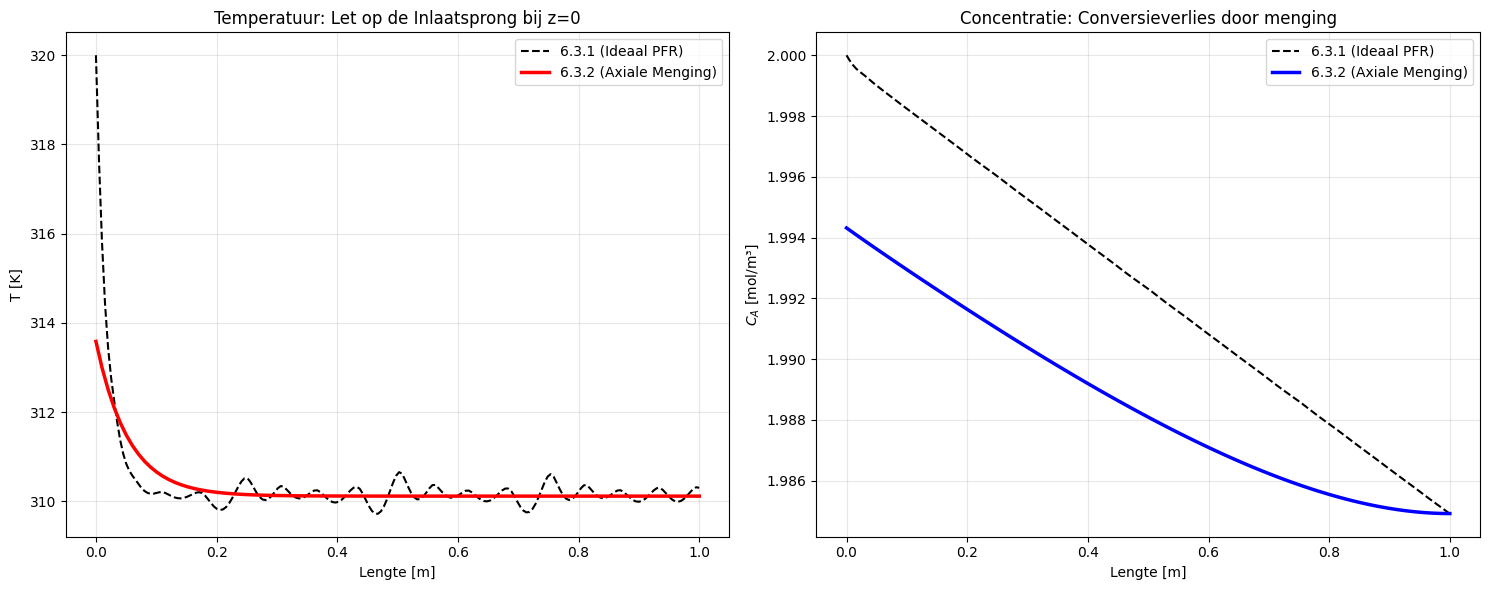

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp

# --- PARAMETERS VOOR ZICHTBARE VERSCHILLEN ---
L = 1.0              # m
v = 0.05             # VEEL TRAGER (0.05 i.p.v. 0.4) -> meer tijd voor menging
rho_cp = 1200.0
delta_rH = -500000.0 # STERKER EXOTHERM -> hogere hot-spot
Tin, Ca0 = 320.0, 2.0
Twtm = 310.0
K_wall, Dr_tube = 40.0, 0.05

# KINETIEK: Sneller gemaakt voor significante conversie
A, Ea = 5e8, 72000.0
R_gas = 8.314

# DISPERSIE: Verhoogd voor een duidelijke inlaatsprong (Lage Peclet)
Da = 0.02           # Axiale massa dispersie [m2/s]
ka = 6.0            # Axiale warmte conductiviteit [W/mK]

# --- MODEL 6.3.1: ODE (Propstroom) ---
def ode_631(z, y):
    Ca, T = y
    k = A * np.exp(-Ea / (R_gas * T))
    ra = -k * Ca
    dCa_dz = ra / v
    dT_dz = (ra * delta_rH - (4*K_wall/Dr_tube)*(T - Twtm)) / (v * rho_cp)
    return [dCa_dz, dT_dz]

sol_631 = solve_ivp(ode_631, [0, L], [Ca0, Tin], t_eval=np.linspace(0, L, 200))

# --- MODEL 6.3.2: BVP (Axiale Menging) ---
def bvp_632(z, y):
    Ca, dCa, T, dT = y
    k = A * np.exp(-Ea / (R_gas * T))
    ra = -k * Ca
    d2Ca = (v * dCa - ra) / Da
    d2T = (v * rho_cp * dT - (ra * delta_rH - (4*K_wall/Dr_tube)*(T - Twtm))) / ka
    return [dCa, d2Ca, dT, d2T]

def bc_632(ya, yb):
    # Danckwerts condities
    return [v*(Ca0 - ya[0]) + Da*ya[1], yb[1], # Massa
            v*rho_cp*(Tin - ya[2]) + ka*ya[3], yb[3]] # Warmte

z_grid = np.linspace(0, L, 100)
# Initiele gok voor BVP solver
y_init = np.zeros((4, 100))
y_init[0,:] = Ca0; y_init[2,:] = Tin

sol_632 = solve_bvp(bvp_632, bc_632, z_grid, y_init)

# --- VISUALISATIE ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Temperatuur: Zoek naar de sprong bij z=0
ax1.plot(sol_631.t, sol_631.y[1], 'k--', label='6.3.1 (Ideaal PFR)')
ax1.plot(sol_632.x, sol_632.y[2], 'r-', lw=2.5, label='6.3.2 (Axiale Menging)')
ax1.set_title('Temperatuur: Let op de Inlaatsprong bij z=0')
ax1.set_ylabel('T [K]')
ax1.legend()

# Concentratie: Zoek naar de "U-bocht" bij de start
ax2.plot(sol_631.t, sol_631.y[0], 'k--', label='6.3.1 (Ideaal PFR)')
ax2.plot(sol_632.x, sol_632.y[0], 'b-', lw=2.5, label='6.3.2 (Axiale Menging)')
ax2.set_title('Concentratie: Conversieverlies door menging')
ax2.set_ylabel('$C_A$ [mol/m³]')
ax2.legend()

for ax in [ax1, ax2]: ax.set_xlabel('Lengte [m]'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

%load_ext itikz
%%itikz --file-prefix reactor-model --implicit-pic
\draw[thick] (0,0) ellipse (1.5cm and 0.5cm);
\begin{tikzpicture}[scale=1.5]
    % Cilinder (Controlevolume dz)
    \draw[thick] (0,0) ellipse (1.5cm and 0.5cm);
    \draw[thick] (0,-2) ellipse (1.5cm and 0.5cm);
    \draw[thick] (-1.5,0) -- (-1.5,-2);
    \draw[thick] (1.5,0) -- (1.5,-2);

    % Bulkstroom (Convectie)
    \draw[-stealth, blue, thick] (0,0.8) -- (0,0.1) node[midway, right] {$v, C_{A,f}, T_f$};
    \draw[-stealth, blue, thick] (0,-2.1) -- (0,-2.8) node[midway, right] {$v (C_{A,f} + \frac{dC_{A,f}}{dz}dz)$};

    % Termen uit 6.24 & 6.26
    \node[blue] at (-2.2, -1) {$\rho_f v c_{pf} \frac{dT_f}{dz}$};
    \node[blue] at (-2.2, -0.6) {$v \frac{dC_{A,f}}{dz}$};

    % Katalysatordeeltjes (De vaste fase)
    \foreach \x/\y in {0.5/-0.8, -0.4/-1.2, 0.2/-1.5, -0.6/-0.5}
        \shade[ball color=gray!40] (\x,\y) circle (0.2cm);
    
    % Interfase transport (6.25 & 6.27)
    \draw[<->, red, thick] (0.5,-0.8) -- (1,-0.8) node[right, scale=0.8] {$\alpha a_v (T_s - T_f)$};
    \draw[<->, green!60!black, thick] (0.5,-1) -- (1,-1) node[right, scale=0.8] {$\beta a_v (C_{A,f} - C_{A,s})$};

    % Wandkoeling (6.26)
    \draw[-stealth, orange, very thick] (1.5, -1) -- (2.2, -1) node[right] {$\frac{4K}{D_r}(T_f - T_{WTM})$};
    
    % Afmeting
    \draw[|<->|] (-1.8, 0) -- (-1.8, -2) node[midway, left] {$dz$};
\end{tikzpicture}

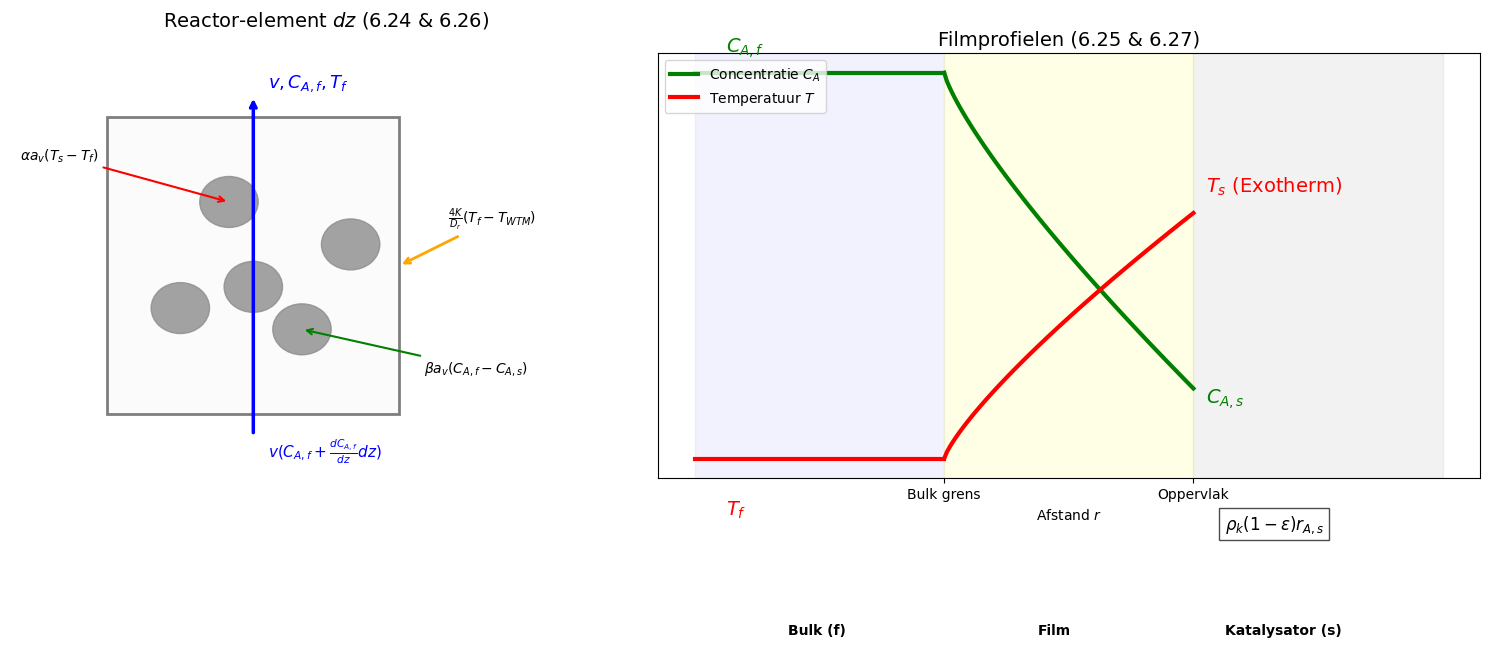

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Setup figuur met twee subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1, 1.3]})

# --- 1. HET CONTROLEVOLUME (CV) ---
ax1.set_title("Reactor-element $dz$ (6.24 & 6.26)", fontsize=14, pad=20)

# Teken de reactorwand (cilinder projectie)
rect = patches.Rectangle((0.2, 0.15), 0.6, 0.7, linewidth=2, edgecolor='black', facecolor='#f9f9f9', alpha=0.5)
ax1.add_patch(rect)

# Bulkstroom pijlen (In en Uit)
ax1.annotate('', xy=(0.5, 0.1), xytext=(0.5, 0.9), arrowprops=dict(arrowstyle='<-', color='blue', lw=2.5))
ax1.text(0.53, 0.92, r'$v, C_{A,f}, T_f$', color='blue', fontsize=13)
ax1.text(0.53, 0.05, r'$v(C_{A,f} + \frac{dC_{A,f}}{dz}dz)$', color='blue', fontsize=11)

# Katalysatorkorreltjes (Vaste fase)
centers = [(0.35, 0.4), (0.6, 0.35), (0.45, 0.65), (0.7, 0.55), (0.5, 0.45)]
for pos in centers:
    ax1.add_patch(plt.Circle(pos, 0.06, color='#8c8c8c', alpha=0.8, label='Vaste fase'))

# Transport termen aanduiden
ax1.annotate(r'$\beta a_v(C_{A,f} - C_{A,s})$', xy=(0.6, 0.35), xytext=(0.85, 0.25),
             arrowprops=dict(arrowstyle='->', color='green', lw=1.5), fontsize=10)
ax1.annotate(r'$\alpha a_v(T_s - T_f)$', xy=(0.45, 0.65), xytext=(0.02, 0.75),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5), fontsize=10)
ax1.annotate(r'$\frac{4K}{D_r}(T_f - T_{WTM})$', xy=(0.8, 0.5), xytext=(0.9, 0.6),
             arrowprops=dict(arrowstyle='->', color='orange', lw=2), fontsize=10)

ax1.set_xlim(0, 1.3); ax1.set_ylim(0, 1); ax1.axis('off')

# --- 2. HET FILMMODEL (GRADIËNTEN) ---
ax2.set_title("Filmprofielen (6.25 & 6.27)", fontsize=14)

# Gebieden markeren
ax2.axvspan(0, 0.4, color='blue', alpha=0.05)   # Bulk
ax2.axvspan(0.4, 0.8, color='yellow', alpha=0.1) # Film
ax2.axvspan(0.8, 1.2, color='gray', alpha=0.1)   # Korrel

ax2.text(0.15, 0.05, 'Bulk (f)', fontweight='bold')
ax2.text(0.55, 0.05, 'Film', fontweight='bold')
ax2.text(0.85, 0.05, 'Katalysator (s)', fontweight='bold')

# Concentratieprofiel (Groen - daalt richting oppervlak)
x_film = np.linspace(0.4, 0.8, 100)
ax2.plot([0, 0.4], [0.85, 0.85], 'g-', lw=3, label='Concentratie $C_A$')
ax2.plot(x_film, 0.85 - 0.45*((x_film-0.4)/0.4)**0.8, 'g-', lw=3)
ax2.text(0.05, 0.88, r'$C_{A,f}$', color='green', fontsize=14)
ax2.text(0.82, 0.38, r'$C_{A,s}$', color='green', fontsize=14)

# Temperatuurprofiel (Rood - stijgt bij exotherm)
ax2.plot([0, 0.4], [0.3, 0.3], 'r-', lw=3, label='Temperatuur $T$')
ax2.plot(x_film, 0.3 + 0.35*((x_film-0.4)/0.4)**0.8, 'r-', lw=3)
ax2.text(0.05, 0.22, r'$T_f$', color='red', fontsize=14)
ax2.text(0.82, 0.68, r'$T_s$ (Exotherm)', color='red', fontsize=14)

# Balans termen op korrel-oppervlak (6.25 & 6.27)
ax2.text(0.85, 0.2, r'$\rho_k (1-\epsilon) r_{A,s}$', fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black'))

ax2.set_xticks([0.4, 0.8]); ax2.set_xticklabels(['Bulk grens', 'Oppervlak'])
ax2.set_yticks([]); ax2.set_xlabel('Afstand $r$')
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

6.3.6: Heterogeen 2D model 

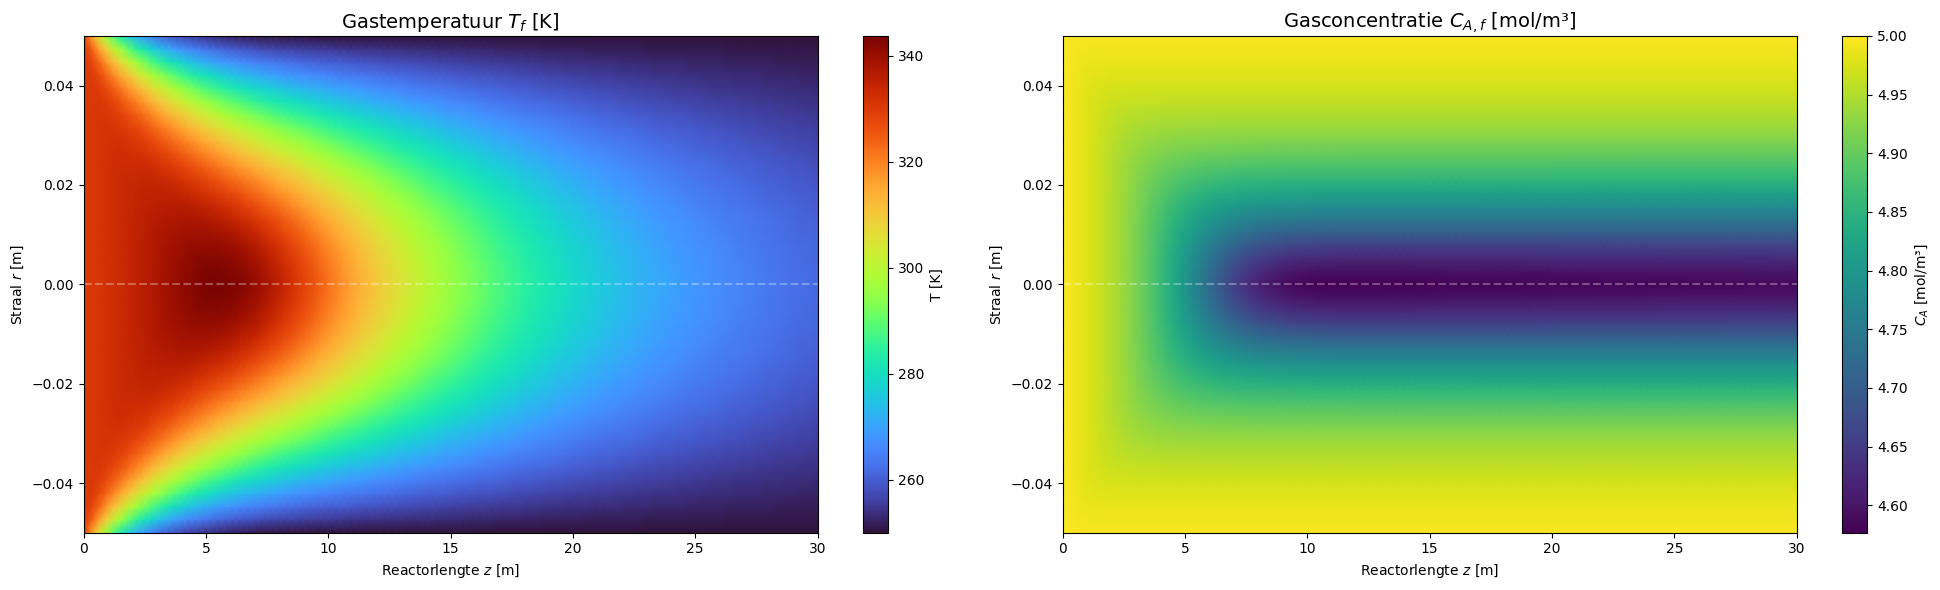

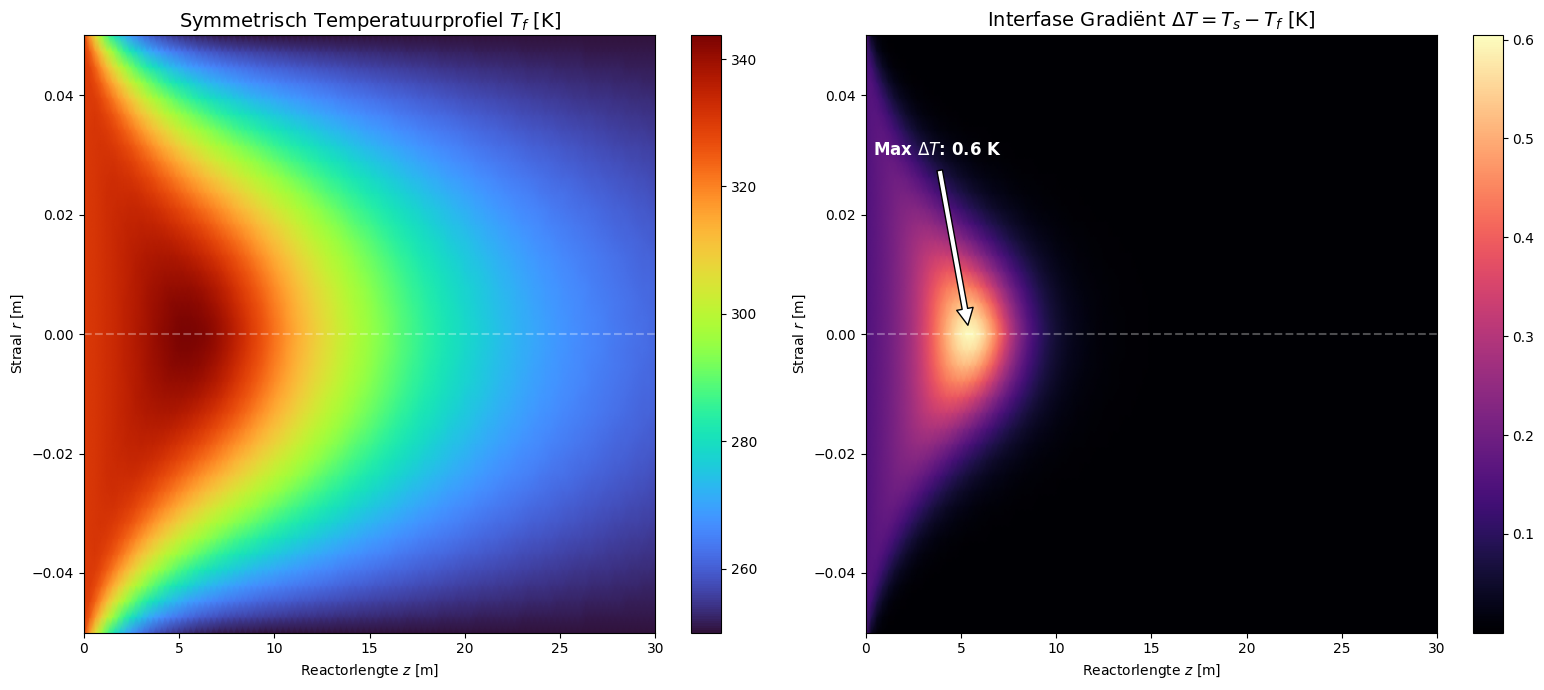

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# --- 1. PARAMETERS ---
L, R = 30.0, 0.05
nr = 20
dr = R / (nr - 1)
r_grid = np.linspace(0, R, nr)

v = 2             # m/s
rho_f, cp_f = 1.0, 1000.0
kr, Dr = 0.8e-1, 2e-7   # Radiale conductiviteit en dispersie
av, beta, alpha = 200.0, 0.04, 120.0
rho_k, eps = 1600.0, 0.6
delta_rH = -95000.0 # Sterk exotherm

# Kinetiek
A, Ea = 1.3e10, 95000.0
R_gas = 8.314

# Randvoorwaarden
Twtm, Tin = 250.0, 330.0
Ca0 = 5.0

# --- 2. DE "SNELLE" FILM-SOLVER ---
def get_surface_conditions(Caf, Tf):
    """Berekent Ts door de massabalans te substitueren in de energiebalans."""
    def energy_residue(Ts_guess):
        k = A * np.exp(-Ea / (R_gas * Ts_guess))
        # Analytische Cas uit vergelijking 6.25
        Cas = (beta * av * Caf) / (beta * av + rho_k * (1 - eps) * k)
        ra_s = -k * Cas
        # Residue van vergelijking 6.27
        return alpha * av * (Ts_guess - Tf) - (rho_k * (1 - eps) * ra_s * delta_rH)

    try:
        # Zoek Ts tussen koeltemperatuur en een veilige bovengrens
        return brentq(energy_residue, 200.0, Tf + 500.0)
    except ValueError:
        return Tf # Fallback indien geen oplossing gevonden

# --- 3. HET 2D PDE MODEL ---
def model_636(z, y):
    Caf = y[:nr]
    Tf = y[nr:]
    dCaf_dz = np.zeros(nr)
    dTf_dz = np.zeros(nr)
    
    for j in range(nr):
        # Stap 1: Bepaal lokale Ts en Cas op basis van bulkcondities
        Ts_j = get_surface_conditions(Caf[j], Tf[j])
        k_s = A * np.exp(-Ea / (R_gas * Ts_j))
        Cas_j = (beta * av * Caf[j]) / (beta * av + rho_k * (1 - eps) * k_s)
        
        # Stap 2: Radiale transport (Finite Differences)
        if j == 0: # Centrum (Symmetrie)
            rad_Ca = 2 * Dr * (Caf[j+1] - Caf[j]) / (dr**2)
            rad_T = 2 * kr * (Tf[j+1] - Tf[j]) / (dr**2)
        elif j == nr - 1: # Wand (Koeling randvoorwaarde)
            rad_Ca = 0
            rad_T = (60.0 / R) * (Twtm - Tf[j])
        else: # Interne ringen
            rad_Ca = Dr * ((Caf[j+1] - 2*Caf[j] + Caf[j-1])/(dr**2) + (1/r_grid[j])*(Caf[j+1]-Caf[j-1])/(2*dr))
            rad_T = kr * ((Tf[j+1] - 2*Tf[j] + Tf[j-1])/(dr**2) + (1/r_grid[j])*(Tf[j+1]-Tf[j-1])/(2*dr))
            
        # Stap 3: Balansen voor de fluïdumfase (Bulk)
        dCaf_dz[j] = (rad_Ca - beta * av * (Caf[j] - Cas_j)) / v
        dTf_dz[j] = (rad_T + alpha * av * (Ts_j - Tf[j])) / (v * rho_f * cp_f)
        
    return np.concatenate([dCaf_dz, dTf_dz])

# --- 4. RUN SIMULATIE ---
y0 = np.concatenate([np.full(nr, Ca0), np.full(nr, Tin)])
z_eval = np.linspace(0, L, 100)
sol = solve_ivp(model_636, (0, L), y0, t_eval=z_eval, method='LSODA')

# --- 6. VOLLEDIGE SYMMETRISCHE VISUALISATIE (Tf, Caf en Delta T) ---

# 1. Maak het symmetrische radiale grid (van -R naar +R)
r_full = np.concatenate([-r_grid[::-1], r_grid[1:]])

# 2. Spiegel de data over de as r=0
# We draaien de rijen om voor het negatieve deel en plakken ze aan het positieve deel
Tf_full = np.concatenate([sol.y[nr:][::-1, :], sol.y[nr+1:, :]], axis=0)
Caf_full = np.concatenate([sol.y[:nr][::-1, :], sol.y[1:nr, :]], axis=0)

# Bereken Ts_full en Delta_T_full voor de heatmap
Ts_full_matrix = np.zeros_like(Tf_full)
for i in range(sol.t.size):
    for j in range(r_full.size):
        # Haal Ts op basis van de gespiegelde bulkwaarden
        Ts_full_matrix[j, i] = get_surface_conditions(Caf_full[j, i], Tf_full[j, i])

Delta_T_full = Ts_full_matrix - Tf_full

# 3. Plotten in 3 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
Z_mesh, R_full_mesh = np.meshgrid(sol.t, r_full)

# Paneel 1: Gastemperatuur Tf
im1 = ax1.pcolormesh(Z_mesh, R_full_mesh, Tf_full, cmap='turbo', shading='gouraud')
ax1.set_title(r'Gastemperatuur $T_f$ [K]', fontsize=14)
plt.colorbar(im1, ax=ax1, label='T [K]')

# Paneel 2: Gasconcentratie Caf
im2 = ax2.pcolormesh(Z_mesh, R_full_mesh, Caf_full, cmap='viridis', shading='gouraud')
ax2.set_title(r'Gasconcentratie $C_{A,f}$ [mol/m³]', fontsize=14)
plt.colorbar(im2, ax=ax2, label='$C_A$ [mol/m³]')


# Algemene layout instellingen
for ax in [ax1, ax2]:
    ax.set_xlabel('Reactorlengte $z$ [m]')
    ax.set_ylabel('Straal $r$ [m]')
    ax.axhline(0, color='white', linestyle='--', alpha=0.3) # Centrale as

plt.tight_layout()
plt.show()

# --- 6. SYMMETRISCHE VISUALISATIE (Spiegelen over r=0) ---

# 1. Maak een symmetrisch radiaal grid: van -R naar +R
r_full = np.concatenate([-r_grid[::-1], r_grid[1:]])

# 2. Spiegel de data voor Tf, Caf en Ts
# We draaien de rijen om voor het negatieve gedeelte en plakken ze aan het positieve
Tf_full = np.concatenate([sol.y[nr:][::-1, :], sol.y[nr+1:, :]], axis=0)
Caf_full = np.concatenate([sol.y[:nr][::-1, :], sol.y[1:nr, :]], axis=0)

# Bereken Delta T opnieuw voor het volledige grid
Ts_full_matrix = np.zeros_like(Tf_full)
for i in range(sol.t.size):
    for j in range(r_full.size):
        Ts_full_matrix[j, i] = get_surface_conditions(Caf_full[j, i], Tf_full[j, i])
Delta_T_full = Ts_full_matrix - Tf_full

# 3. Plotten
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
Z_mesh, R_full_mesh = np.meshgrid(sol.t, r_full)

# Heatmap Temperatuur
im1 = ax1.pcolormesh(Z_mesh, R_full_mesh, Tf_full, cmap='turbo', shading='gouraud')
ax1.set_title(rf'Symmetrisch Temperatuurprofiel $T_f$ [K]', fontsize=14)
plt.colorbar(im1, ax=ax1)

# Heatmap Delta T (Interfase gradiënt)
im2 = ax2.pcolormesh(Z_mesh, R_full_mesh, Delta_T_full, cmap='magma', shading='gouraud')
ax2.set_title(r'Interfase Gradiënt $\Delta T = T_s - T_f$ [K]', fontsize=14)
plt.colorbar(im2, ax=ax2)

# Annotatie met 'rf' om SyntaxWarnings te vermijden
max_dt = np.max(Delta_T_full)
ax2.annotate(rf'Max $\Delta T$: {max_dt:.1f} K', 
             xy=(sol.t[np.argmax(Delta_T_full)%sol.t.size], 0), 
             xytext=(0.4, 0.03),
             arrowprops=dict(facecolor='white', shrink=0.05), 
             color='white', fontweight='bold', fontsize=12)

for ax in [ax1, ax2]:
    ax.set_xlabel('Reactorlengte $z$ [m]')
    ax.set_ylabel('Straal $r$ [m]')
    ax.axhline(0, color='white', linestyle='--', alpha=0.3) # Centrale as aanduiden

plt.tight_layout()
plt.show()

OEF 20

In [144]:
import sympy as sp

# 1. Definieer je symbool
T = sp.symbols('T')

# 2. De parameters
k_ref = 10**-3
T_ref = 300.15 # In Kelvin
Ea = 9.95      # kcal/mol
R = 0.001987   # kcal/(mol.K) -> Let op de eenheid! kcal ipv cal

# 3. De doelsnelheid (k_target) berekenen
# X = 0.5, tau = 0.5/2 = 0.25
k_target = 0.5 / (0.25 * (1 - 0.5)) # Dit is 4.0

# 4. Stel de vergelijking op: k_target = k_ref * exp(...)
vergelijking = sp.Eq(k_target, k_ref * sp.exp((Ea/R) * (1/T_ref - 1/T)))

# 5. Los op
opl = sp.solve(vergelijking, T)

# Resultaat
print(f"De reactortemperatuur is: {float(opl[0]):.2f} K")

KeyboardInterrupt: 

Hier wordt het principe van de hysterese in recatorstabiliteit getoond.
De warmtebalans voor een CSTR is als volgt:
\begin{align}
    & \frac{r\cdot \Delta_rH\cdot V}{mc_p}=\left(1+\frac{KA}{mc_p}\right)T - \left(T_O +\frac{KA}{mc_p}T_{WTM}\right)\\
    & Q_T = A\cdot T + T_0 + B\\
\end{align}

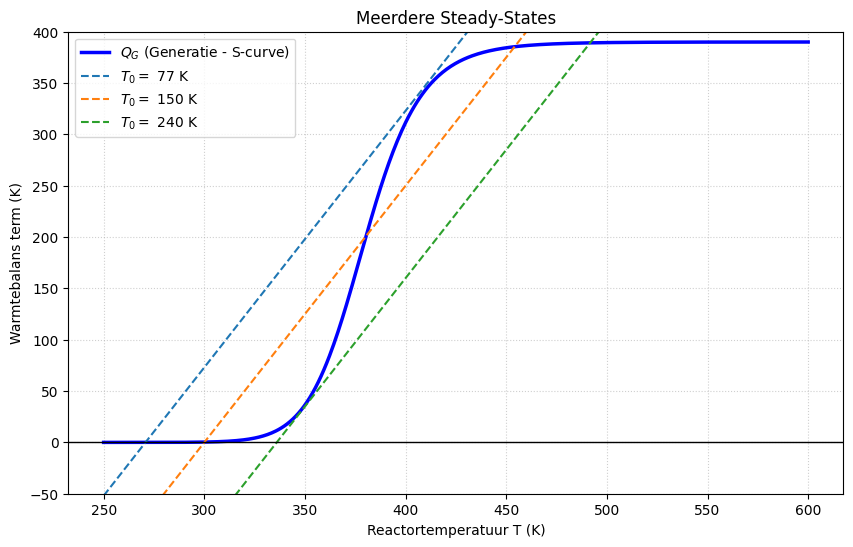

In [37]:
import numpy as np
import matplotlib.pyplot as plt
# Parameters aangepast voor betere proporties (gebaseerd op theorie hfdst 5)
H_abs = -60000      # kJ/kmol
V = 10             # m3
m_dot = 10         # kg/s
c_p = 2            # kJ/kgK
KA = 30            # kW/K (was 10000 W/K, nu consistent in kJ/sK)
T_WTM = 400        # K (koelwatertemperatuur iets verlaagd)
T_0 = 360          # K (ingangstemperatuur)
Ea = 85000         # kJ/kmol (iets hoger voor een duidelijkere S-curve)
R = 8.314          # kJ/kmolK
A = 5e8            # 1/s (aangepast voor verschuiving S-curve)
Ca0 = 13.0         # kmol/m3 (verhoogd naar 10 voor hogere warmte-output)
rho = 1000         # kg/m3

# Afgeleide waarden
tau = V / (m_dot / rho)  # Verblijftijd
term_KA = KA / (m_dot * c_p)

# Temperatuur range
T = np.linspace(250, 600, 500)

# 1. Kinetiek (CSTR stationaire balans)
k = A * np.exp(-Ea / (R * T))
Ca = Ca0 / (1 + k * tau) 
r_abs = -k * Ca

plt.figure(figsize=(10, 6))
plt.plot(T, QG, label='$Q_G$ (Generatie - S-curve)', color='blue', lw=2.5)

# 2. QG (Warmtegeneratie curve) - zie vergelijking 5.32 [4]
QG = (r_abs * V * H_abs) / (m_dot * c_p)
T_0=[77,150,240]
for T_in in T_0:
    # 3. QH (Warmte-afvoer lijn) - zie vergelijking 5.32 [4]
    QH = (1 + term_KA) * T - (T_in + term_KA * T_WTM)
    plt.plot(T,QH,label=rf'$T_{0}=$ {T_in} K', linestyle='--')


plt.ylim(-50, 400) # y-as begrenzen voor overzicht
plt.xlabel('Reactortemperatuur T (K)')
plt.ylabel('Warmtebalans term (K)')
plt.title('Meerdere Steady-States')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.axhline(0, color='black', lw=1)
plt.show()